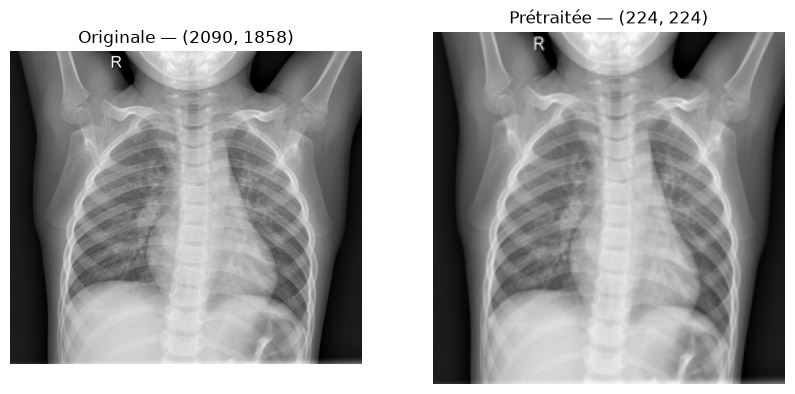

Min pixel value: 0.0
Max pixel value: 0.9764706


In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = os.path.join("..", "data")
IMG_SIZE = (224, 224)  # taille cible standard pour beaucoup de CNN / Transfer Learning

def load_and_preprocess(img_path, target_size=IMG_SIZE):
    img = Image.open(img_path)
    img = img.convert("L")           # s'assurer que c'est bien en niveaux de gris
    img = img.resize(target_size)    # redimensionner à une taille fixe
    arr = np.array(img, dtype=np.float32)
    arr = arr / 255.0                # normalisation : pixels entre 0 et 1
    return arr

# Test sur une image
sample_path = os.path.join(DATA_DIR, "train", "NORMAL", 
                            os.listdir(os.path.join(DATA_DIR, "train", "NORMAL"))[0])

original = Image.open(sample_path)
processed = load_and_preprocess(sample_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(original, cmap="gray")
axes[0].set_title(f"Originale — {original.size}")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title(f"Prétraitée — {processed.shape}")
axes[1].axis("off")

plt.show()

print("Min pixel value:", processed.min())
print("Max pixel value:", processed.max())

In [2]:
import time

def load_dataset_sample(split, cls, n=50):
    folder = os.path.join(DATA_DIR, split, cls)
    files = [f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))][:n]
    
    images = []
    for f in files:
        img_path = os.path.join(folder, f)
        images.append(load_and_preprocess(img_path))
    
    return np.array(images)

start = time.time()
sample = load_dataset_sample("train", "NORMAL", n=50)
elapsed = time.time() - start

print(f"Shape du batch: {sample.shape}")
print(f"Temps pour 50 images: {elapsed:.2f} secondes")
print(f"Temps estimé pour tout le train (4434 images): {elapsed / 50 * 4434 / 60:.1f} minutes")

Shape du batch: (50, 224, 224)
Temps pour 50 images: 0.67 secondes
Temps estimé pour tout le train (4434 images): 1.0 minutes


In [3]:
def load_full_dataset(split):
    X, y = [], []
    for label_idx, cls in enumerate(CLASSES):  # NORMAL=0, PNEUMONIA=1
        folder = os.path.join(DATA_DIR, split, cls)
        files = [f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))]
        for f in files:
            img_path = os.path.join(folder, f)
            X.append(load_and_preprocess(img_path))
            y.append(label_idx)
    return np.array(X), np.array(y)

CLASSES = ["NORMAL", "PNEUMONIA"]  # NORMAL=0, PNEUMONIA=1

os.makedirs(os.path.join(DATA_DIR, "processed"), exist_ok=True)

for split in ["train", "validation", "test"]:
    print(f"Traitement de {split}...")
    start = time.time()
    X, y = load_full_dataset(split)
    elapsed = time.time() - start
    
    np.save(os.path.join(DATA_DIR, "processed", f"X_{split}.npy"), X)
    np.save(os.path.join(DATA_DIR, "processed", f"y_{split}.npy"), y)
    
    print(f"  X shape: {X.shape}, y shape: {y.shape} — {elapsed:.1f}s")

Traitement de train...
  X shape: (4434, 224, 224), y shape: (4434,) — 34.8s
Traitement de validation...
  X shape: (782, 224, 224), y shape: (782,) — 11.2s
Traitement de test...
  X shape: (624, 224, 224), y shape: (624,) — 4.9s


In [4]:
processed_dir = os.path.join(DATA_DIR, "processed")
for f in sorted(os.listdir(processed_dir)):
    path = os.path.join(processed_dir, f)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{f} — {size_mb:.1f} MB")
    

X_test.npy — 119.4 MB
X_train.npy — 848.7 MB
X_validation.npy — 149.7 MB
y_test.npy — 0.0 MB
y_train.npy — 0.0 MB
y_validation.npy — 0.0 MB
